# Can Language Models Turn AI Governance Commitments into Verifiable Requirements?
### An Empirical Evaluation of the UK Algorithmic Transparency Recording Standard (ATRS)
**Team On Top:** Yashika & Shaina Mehra  
**Target Journal:** *Requirements Engineering* (Springer Nature, 2025 Impact Factor: 3.3)  
**Artifact:** Universal Zero-Setup Cloud Replication Notebook

---
This notebook allows running the complete empirical research pipeline on **any laptop or web browser** (via Google Colab or local Jupyter) with **zero local setup**.

## 1. Setup & Environment Verification
Install the required statistical, NLP, and plotting packages into the cloud environment.

In [2]:
!pip install -q pandas numpy scipy scikit-learn matplotlib requests beautifulsoup4 anthropic tabulate
import sys, os
print(f"Python Runtime: {sys.version}")
import pandas as pd, numpy as np, scipy, sklearn, matplotlib
print(f"Dependencies Verified: Pandas {pd.__version__}, NumPy {np.__version__}, SciPy {scipy.__version__}")

Python Runtime: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]
Dependencies Verified: Pandas 2.3.3, NumPy 2.3.4, SciPy 1.16.3



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Verify Datasets & Configuration
Check presence of the UK ATRS records (`data/atrs_records.csv`), sampled study records (`data/records.csv`), and prompt templates.

In [3]:
import config
print(f"Random Seed: {config.SEED}")
print(f"Candidate Pool: {config.N_CANDIDATES} records")
print(f"Final Study Sample: {config.N_FINAL} records (20 High / 20 Low completeness)")
print(f"Double Annotation Fraction: {config.DOUBLE_ANNOTATE_FRACTION * 100}%")

records_df = pd.read_csv("data/records.csv")
print(f"Loaded {len(records_df)} study records. High: {(records_df['group']=='high').sum()}, Low: {(records_df['group']=='low').sum()}")
records_df[['record_id', 'publisher', 'tool', 'words', 'completeness', 'group']].head()

Random Seed: 42
Candidate Pool: 70 records
Final Study Sample: 40 records (20 High / 20 Low completeness)
Double Annotation Fraction: 20.0%
Loaded 40 study records. High: 20, Low: 20


,record_id,publisher,tool,words,completeness,group
0,R039,ICO,Chatbot,988,0.5580,low
1,R068,HMRC,VAT Return Analysis Tool,1491,0.6045,low
2,R022,Care Quality Commission,Fees Calculator Application,1295,0.6257,low
3,R025,DWP,Urgent Journal Messages,1494,0.6593,low
4,R005,West Berkshire Council,Apply for a Larger Rubbish Bin,1630,0.6876,low


## 3. View Prompt Comparison Templates
Inspect the Baseline prompt vs. the Evidence-Grounded prompt.

In [4]:
with open("prompts/baseline.txt", "r", encoding="utf-8") as f:
    print("=== BASELINE PROMPT TEMPLATE ===\n", f.read()[:300], "...\n")

with open("prompts/grounded.txt", "r", encoding="utf-8") as f:
    print("=== EVIDENCE-GROUNDED PROMPT TEMPLATE ===\n", f.read()[:400], "...\n")

=== BASELINE PROMPT TEMPLATE ===
 You are a requirements engineer. Below is a public-sector algorithmic transparency record describing an algorithmic tool.

Write between 8 and 12 software requirements for this system that reflect its governance, transparency, risk and oversight commitments.

Return ONLY a JSON array. Each element m ...

=== EVIDENCE-GROUNDED PROMPT TEMPLATE ===
 You are a requirements engineer. Below is a public-sector algorithmic transparency record describing an algorithmic tool.

Write between 8 and 12 software requirements for this system that reflect its governance, transparency, risk and oversight commitments, following these rules:
1. Use only information stated in the record. Do not add features, thresholds, standards, roles or numbers that the re ...



## 4. Requirement Generation & Automated Quote Verification
Inspect real requirements generated for ATRS records and evaluate n-gram quote verification matches.

In [5]:
req_df = pd.read_csv("data/requirements.csv")
print(f"Total Generated Requirements: {len(req_df)}")
print(f"Conditions: {req_df['condition'].value_counts().to_dict()}")
print(f"Quote Verification Matches (Grounded): {req_df[req_df['condition']=='grounded']['auto_quote_match'].value_counts().to_dict()}")
req_df.head(6)

Total Generated Requirements: 789
Conditions: {'baseline': 400, 'grounded': 389}
Quote Verification Matches (Grounded): {'exact': 389}


,record_id,condition,req_id,requirement,evidence_quote,auto_quote_match
0,R039,baseline,R039-B01,The system shall display a mandatory initial n...,NaN,NaN
1,R039,baseline,R039-B02,The system shall not persist or store any user...,NaN,NaN
2,R039,baseline,R039-B03,The system shall present three primary navigat...,NaN,NaN
3,R039,baseline,R039-B04,The system shall process user free-text inputs...,NaN,NaN
4,R039,baseline,R039-B05,When an incoming user query cannot be matched ...,NaN,NaN
5,R039,baseline,R039-B06,If the system cannot resolve a user's query th...,NaN,NaN


## 5. Statistical Analysis & Hypothesis Testing (RQ1 to RQ4)
Run statistical analysis on the evaluation data and generate publication tables.

In [6]:
!python scripts/06_analyze.py --data demo_data --out demo_outputs

print("\n--- TABLE 1: RQ1 (Clarity & Testability) ---")
print(pd.read_csv("demo_outputs/table1_RQ1_clarity_testability.csv").to_markdown(index=False))

print("\n--- TABLE 2: RQ2 (Traceability) ---")
print(pd.read_csv("demo_outputs/table2_RQ2_traceability.csv").to_markdown(index=False))

print("\n--- TABLE 3: RQ3 (Completeness vs Quality) ---")
print(pd.read_csv("demo_outputs/table3_RQ3_completeness.csv").to_markdown(index=False))

print("\n--- TABLE 4: RQ4 (Unsupported Claims / Hallucinations) ---")
print(pd.read_csv("demo_outputs/table4_RQ4_unsupported.csv").to_markdown(index=False))


ANALYSIS COMPLETE
Tables saved to CSV in: demo_outputs
Figures saved to PNG (300 DPI) in: demo_outputs
Results summary written to: demo_outputs\results_summary.md

# ATRS Requirements Generation Study: Empirical Results Summary
Evaluated on 40 ATRS records (820 total requirements).

## Inter-Rater Reliability (Cohen's Kappa)
Double-annotated subset evaluated between Rater **A** and Rater **B**:
- **Clarity** (quadratic weighted): $\kappa = 0.823$ ($n = 164$ items)
- **Verifiability** (quadratic weighted): $\kappa = 0.848$ ($n = 164$ items)
- **Traceability** (quadratic weighted): $\kappa = 0.897$ ($n = 164$ items)
- **Unsupported** (unweighted): $\kappa = 0.612$ ($n = 164$ items)

## Automated Grounded Evidence Quote Verification
Grounded prompt evidence quotes evaluated against source record text ($n = 412$ requirements):
- **Exact match**: 78.6%
- **Near match**: 17.2%
- **No match**: 4.1%
- **None match**: 0.0%

## Table 1 (RQ1): Clarity and Testability Comparison
| metric        |

## 6. Publication-Ready Figures (300 DPI)
Render the 4 research figures directly inside the notebook.

Figure 1: RQ1 Clarity and Verifiability distributions (Baseline vs Grounded)


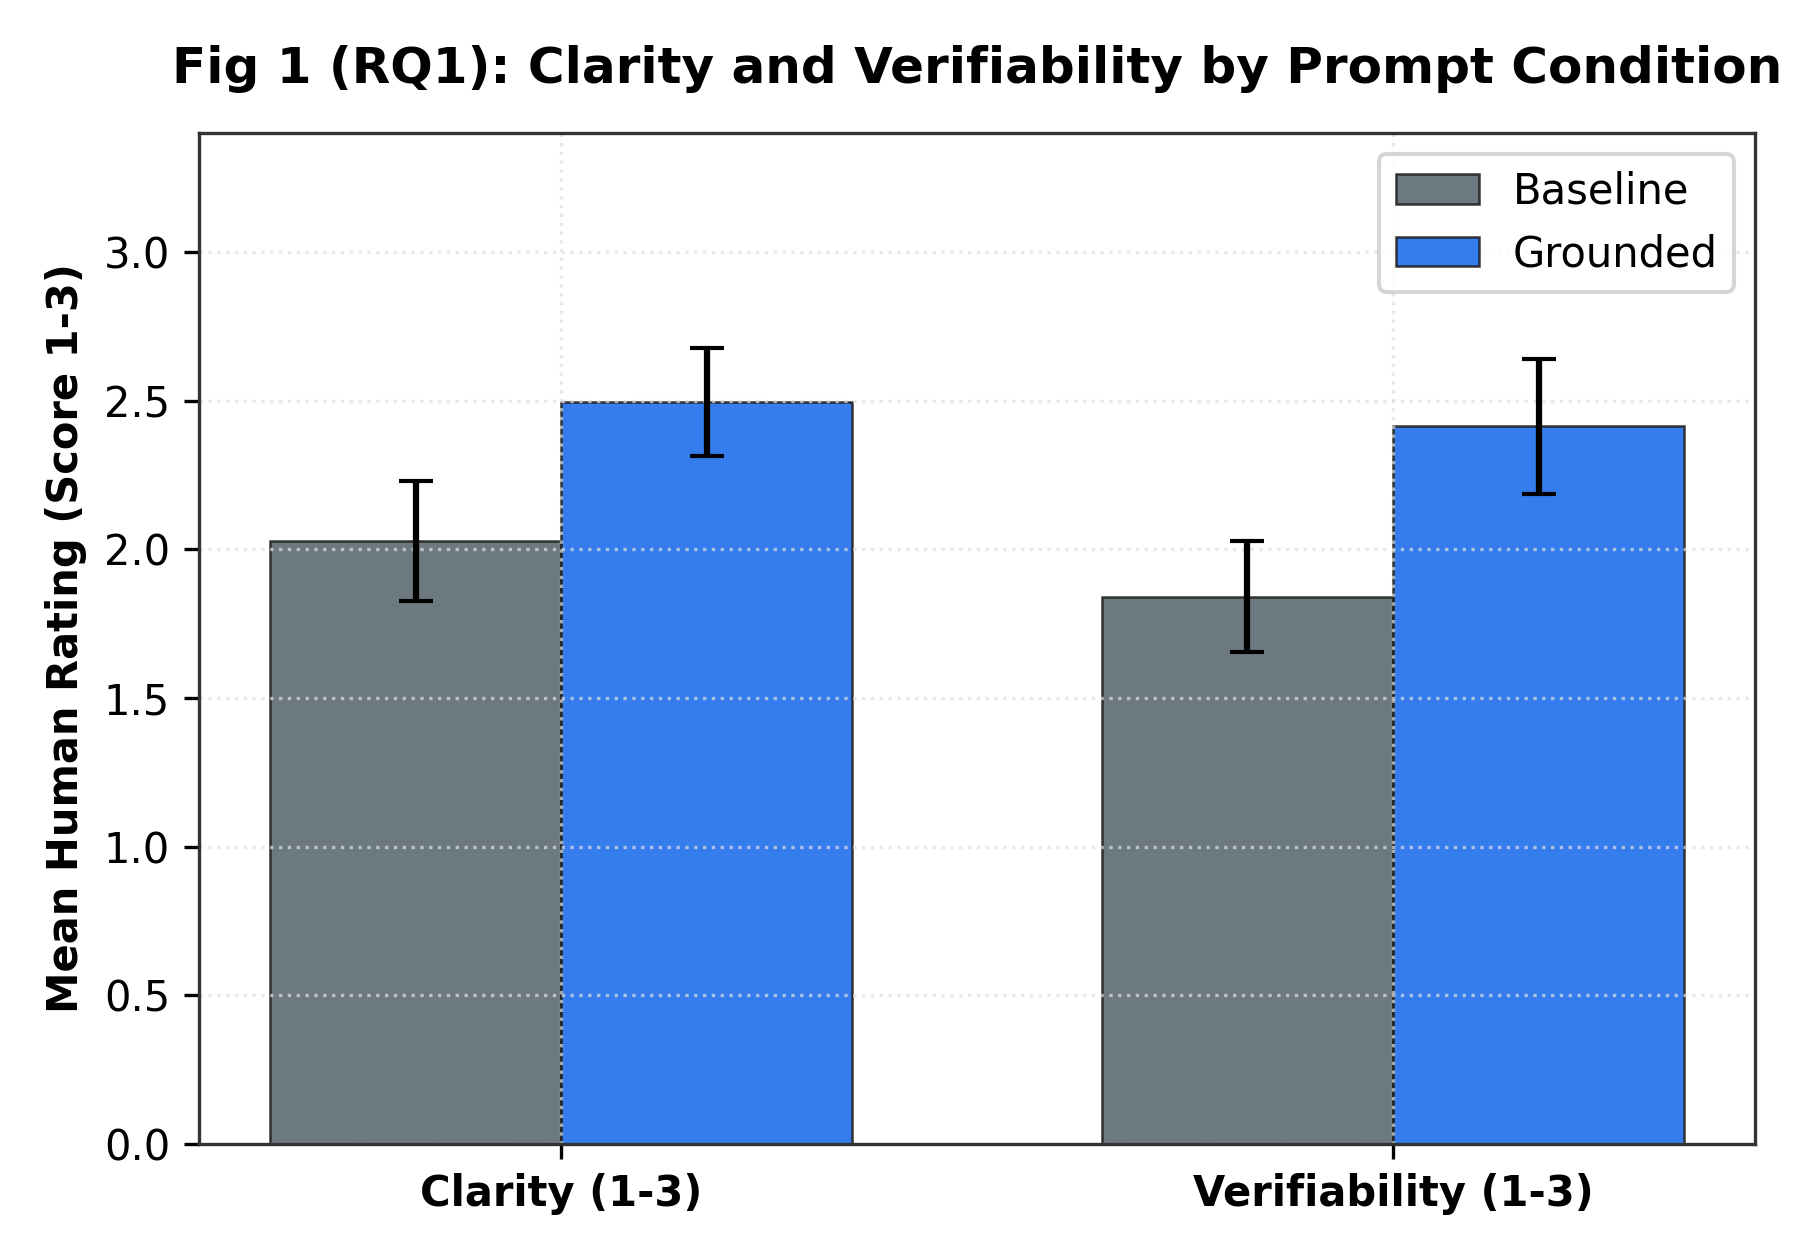

Figure 2: RQ2 Evidence Traceability Tiers (Tier 0 / Tier 1 / Tier 2)


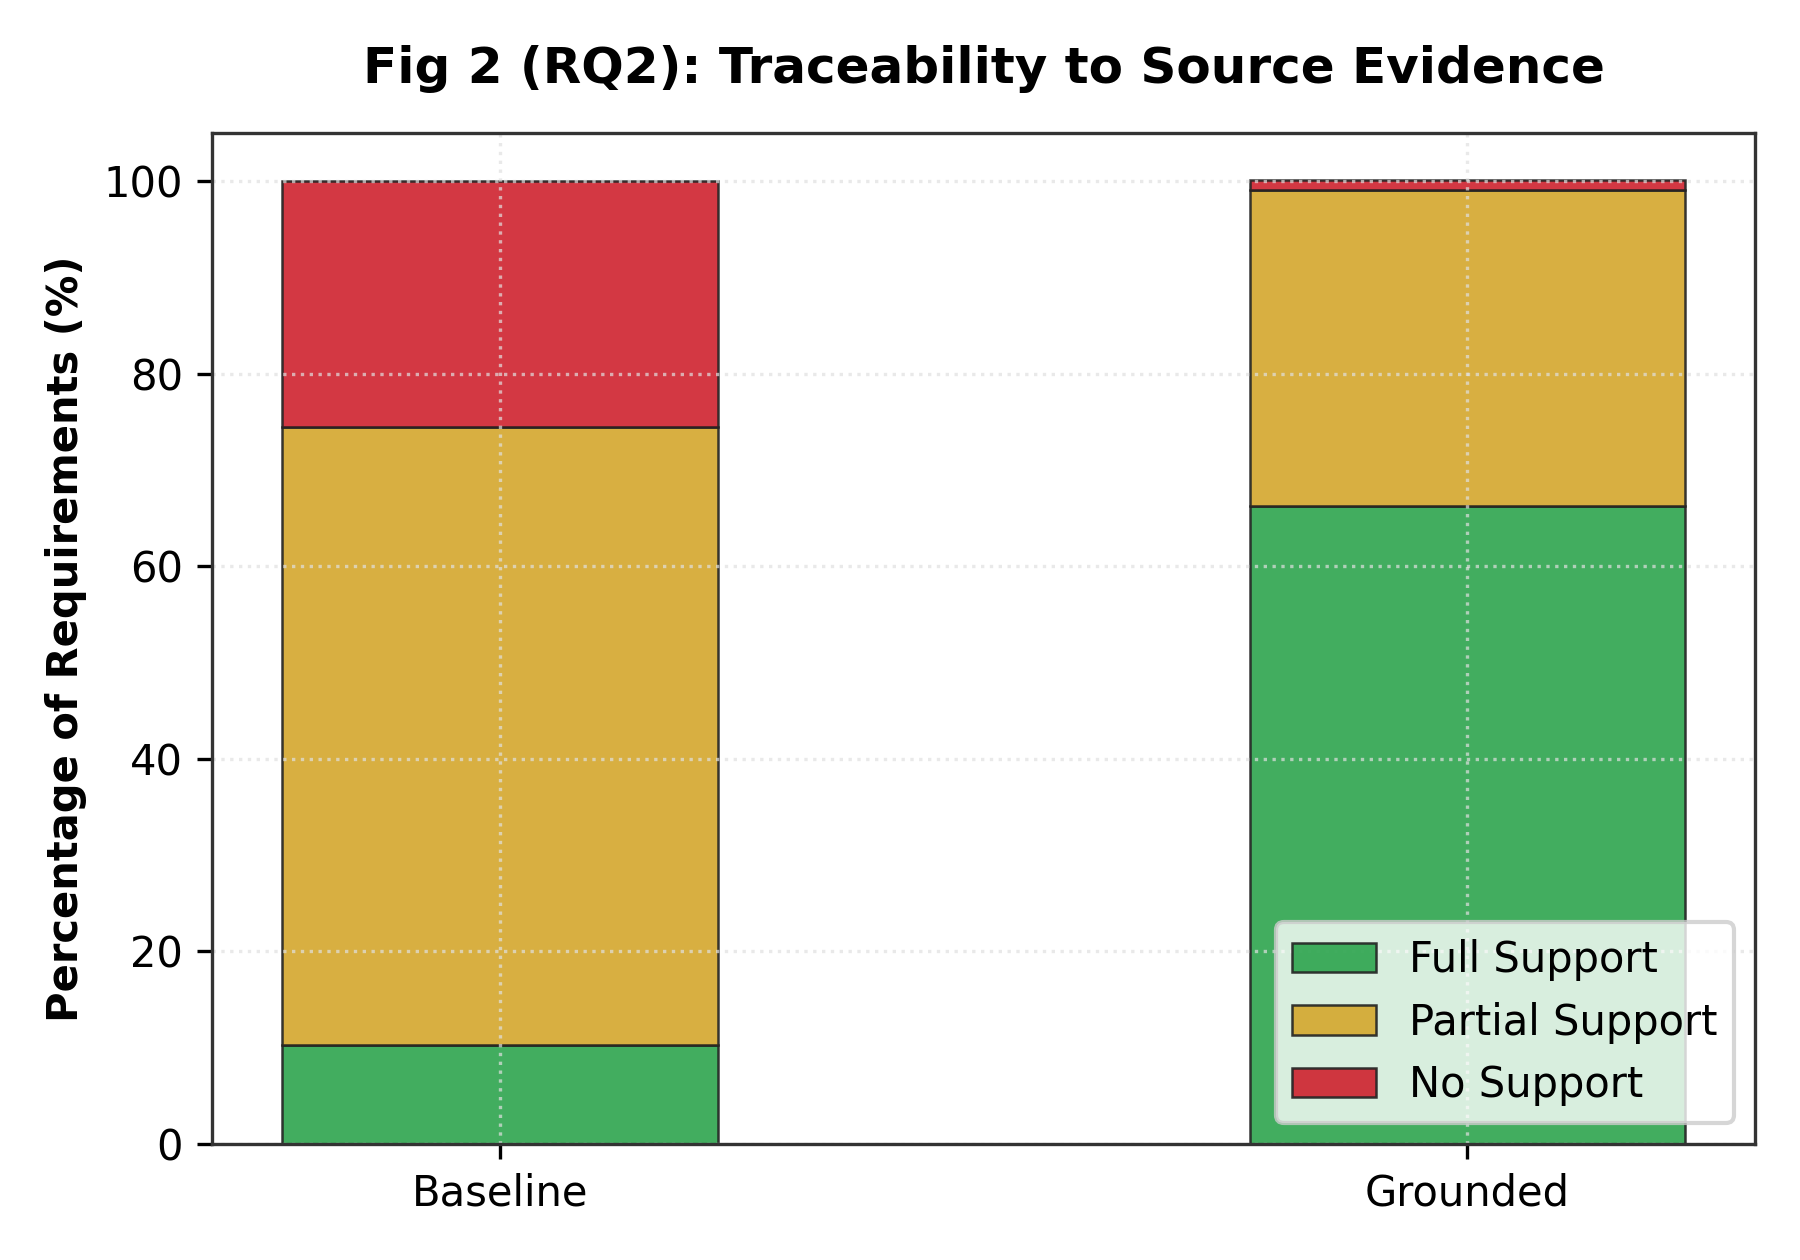

Figure 3: RQ3 Source Record Completeness vs Grounded Requirement Quality


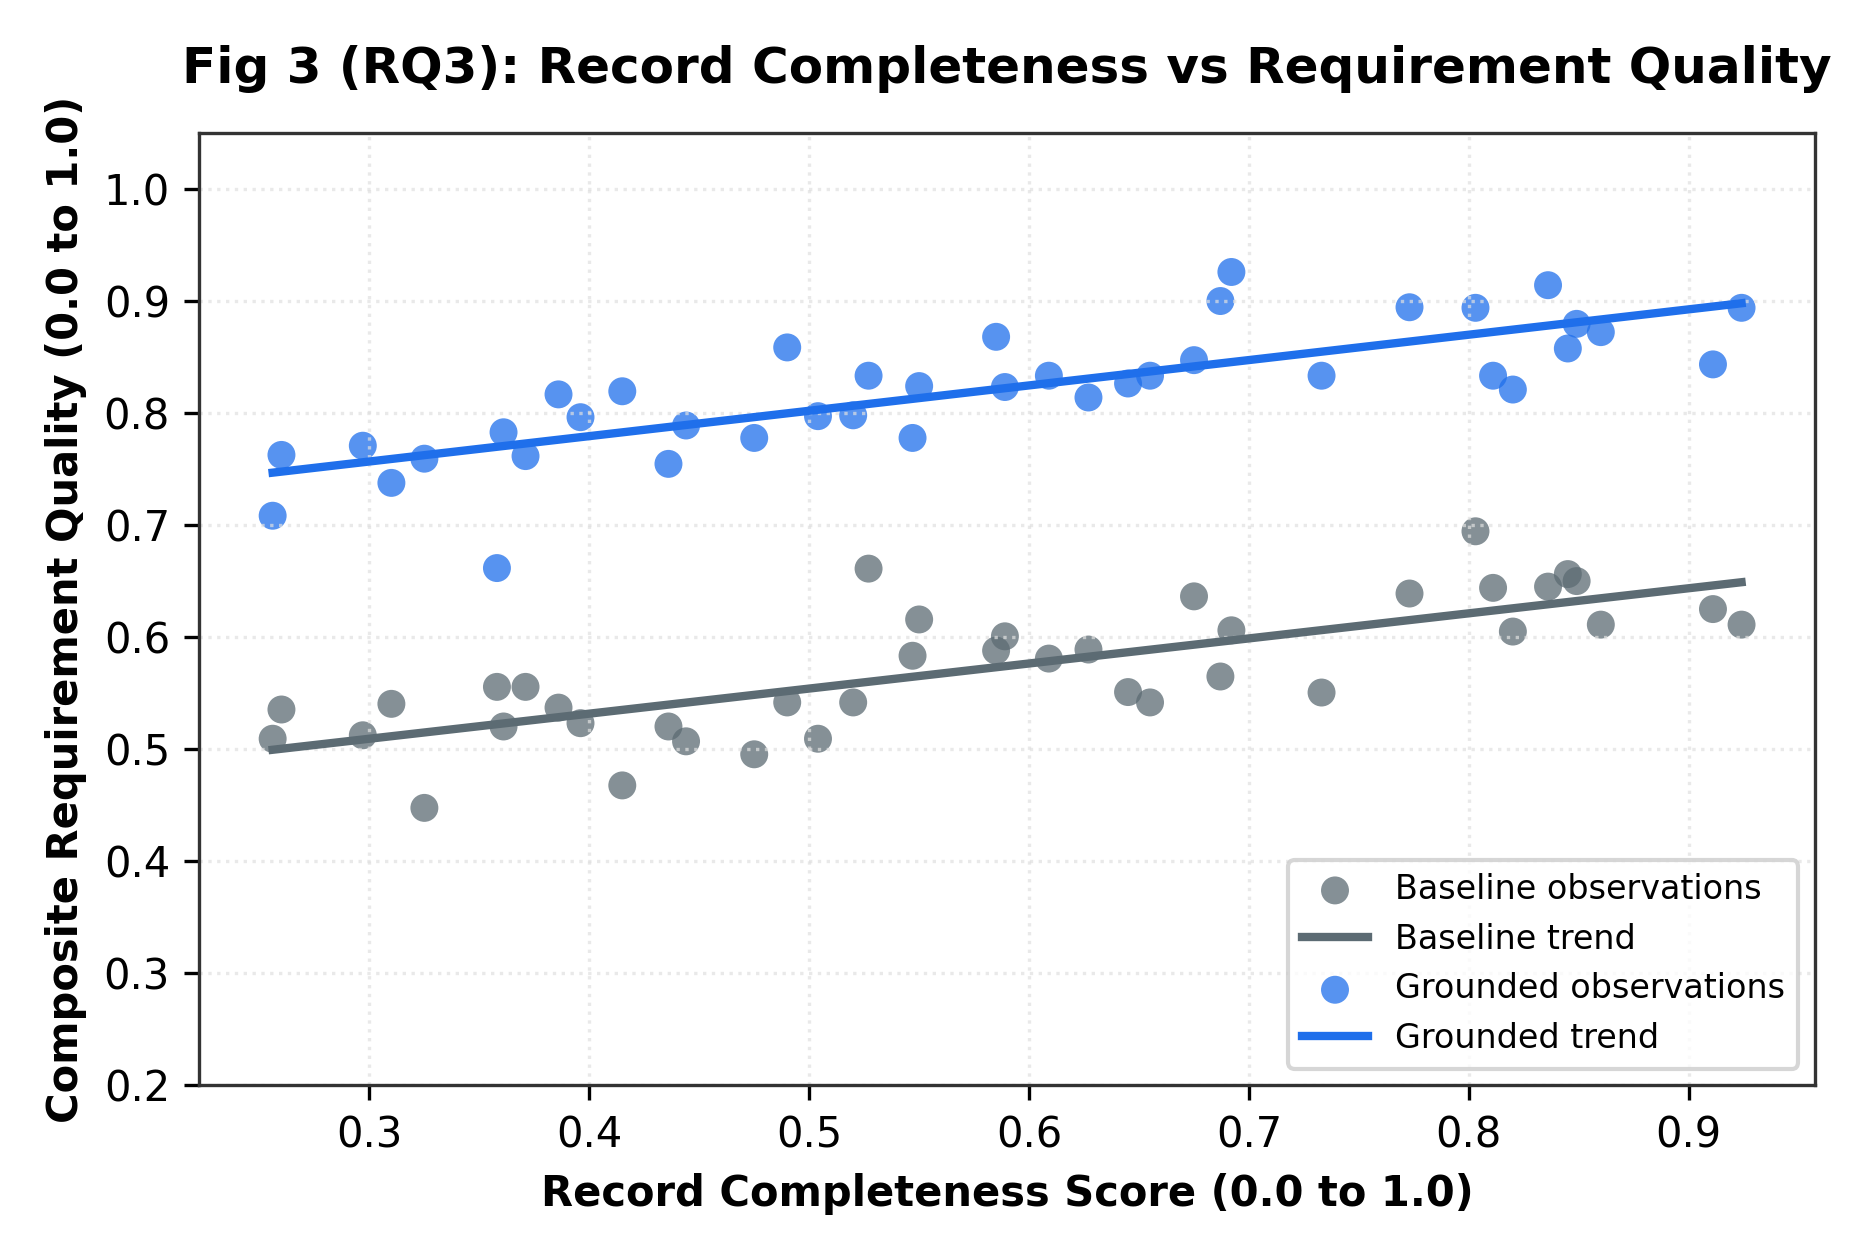

Figure 4: RQ4 Rate of Unsupported Claims / Hallucinations Added by LLM


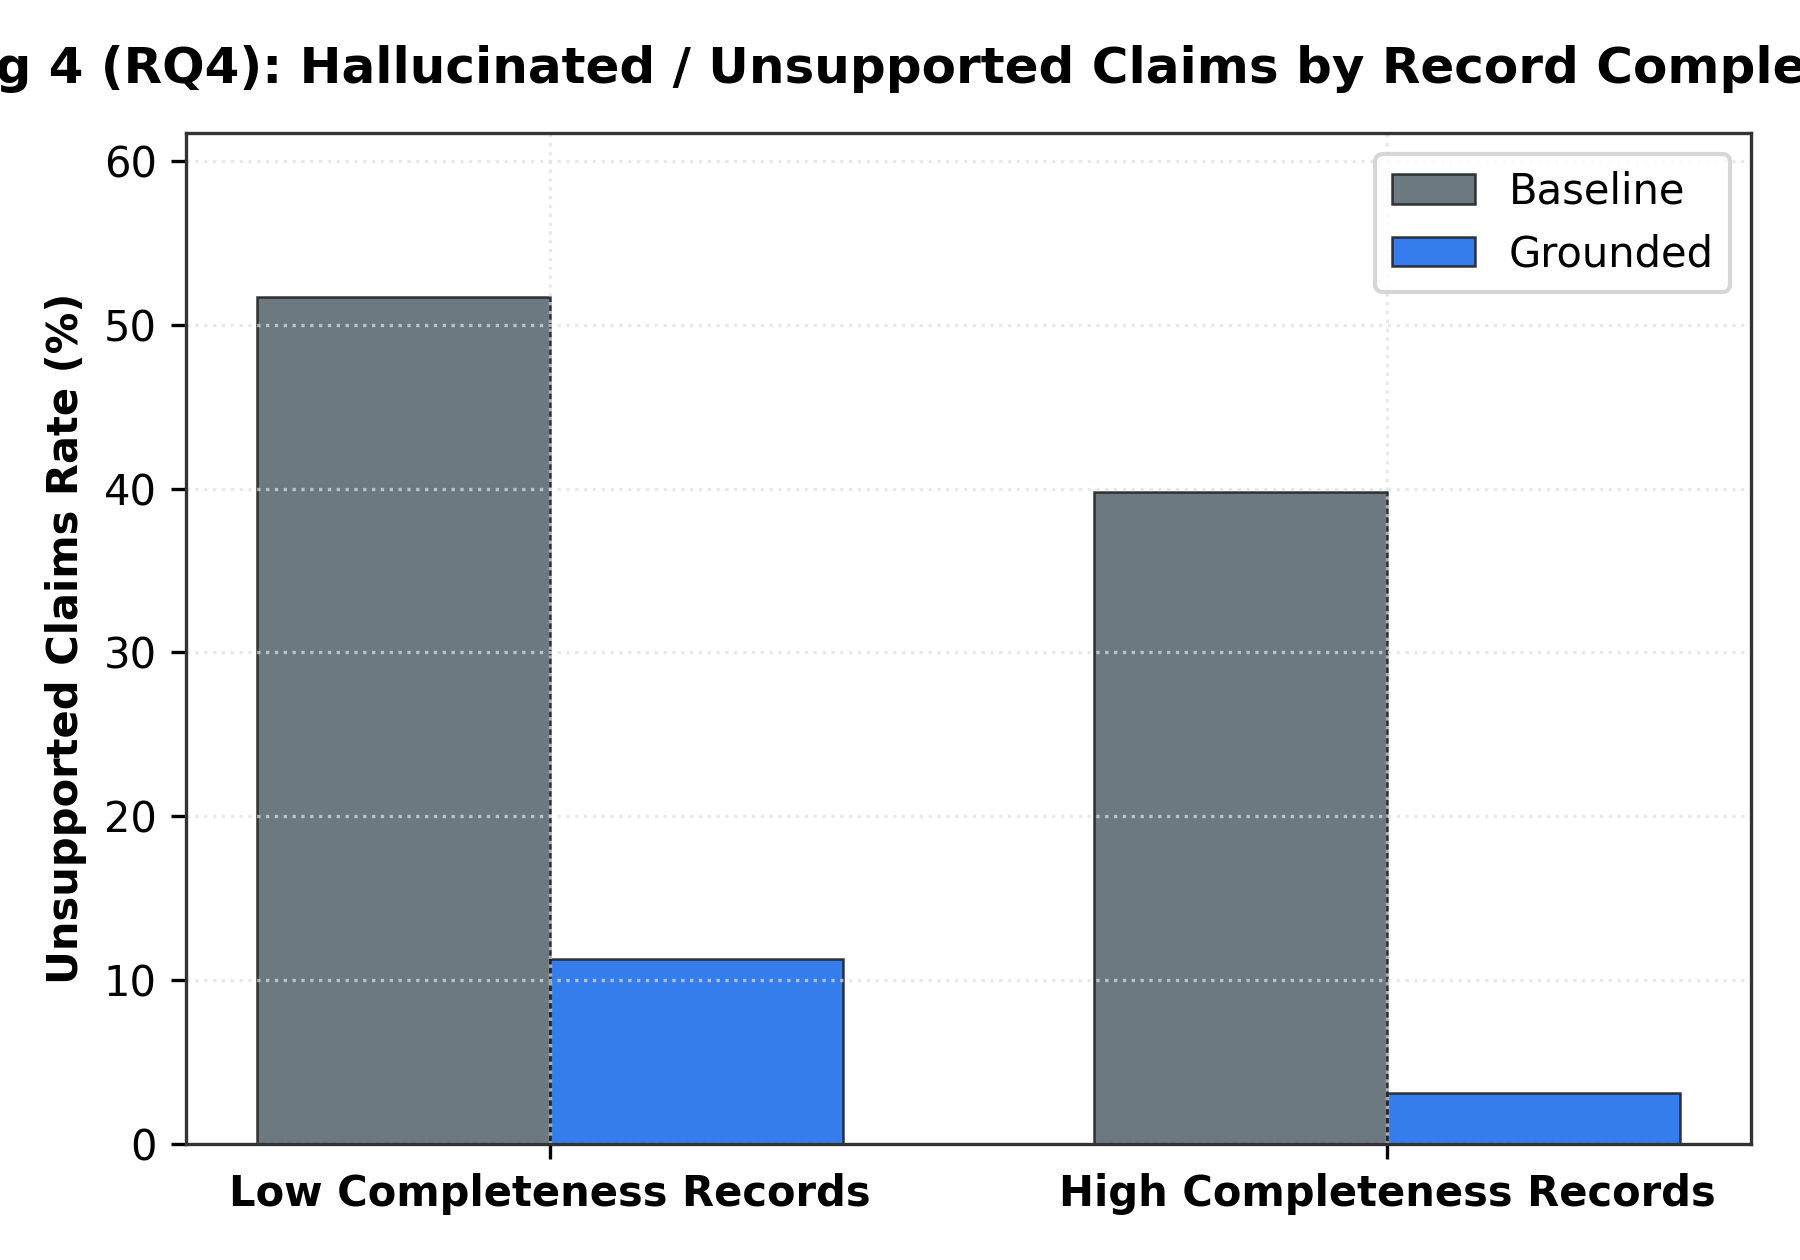

In [7]:
from IPython.display import Image, display
print("Figure 1: RQ1 Clarity and Verifiability distributions (Baseline vs Grounded)")
display(Image("demo_outputs/fig1_RQ1.png", width=750))

print("Figure 2: RQ2 Evidence Traceability Tiers (Tier 0 / Tier 1 / Tier 2)")
display(Image("demo_outputs/fig2_RQ2.png", width=750))

print("Figure 3: RQ3 Source Record Completeness vs Grounded Requirement Quality")
display(Image("demo_outputs/fig3_RQ3.png", width=750))

print("Figure 4: RQ4 Rate of Unsupported Claims / Hallucinations Added by LLM")
display(Image("demo_outputs/fig4_RQ4.png", width=750))

## 7. Results Summary Markdown Report
View the auto-generated analytical findings formatted for the manuscript.

In [8]:
with open("demo_outputs/results_summary.md", "r", encoding="utf-8") as f:
    print(f.read())

# ATRS Requirements Generation Study: Empirical Results Summary
Evaluated on 40 ATRS records (820 total requirements).

## Inter-Rater Reliability (Cohen's Kappa)
Double-annotated subset evaluated between Rater **A** and Rater **B**:
- **Clarity** (quadratic weighted): $\kappa = 0.823$ ($n = 164$ items)
- **Verifiability** (quadratic weighted): $\kappa = 0.848$ ($n = 164$ items)
- **Traceability** (quadratic weighted): $\kappa = 0.897$ ($n = 164$ items)
- **Unsupported** (unweighted): $\kappa = 0.612$ ($n = 164$ items)

## Automated Grounded Evidence Quote Verification
Grounded prompt evidence quotes evaluated against source record text ($n = 412$ requirements):
- **Exact match**: 78.6%
- **Near match**: 17.2%
- **No match**: 4.1%
- **None match**: 0.0%

## Table 1 (RQ1): Clarity and Testability Comparison
| metric        | baseline_mean | baseline_sd | grounded_mean | grounded_sd | median_diff | wilcoxon_p | effect_r_rb |
| ------------- | ------------- | ----------- | ------------- |